# Занятие 4 — классификатор, генератор и блок трансформера

Автор: Daria Andreeva.

Соберём три модели из концептов первых трёх занятий. В каждом блоке: схема → вход и цель → модель → обучение → проверка. Код моделей пишем сами на PyTorch. Встроенный attention используем только для сверки; готовые векторы слов скачиваем через gensim.

Данные: англоязычные новости AG News для классификации и анекдоты DSBA для генерации (в корпусе встречается ненормативная лексика). Берём небольшие подвыборки. Эти запуски показывают полный путь обучения; качество большой модели по ним не оцениваем.

[Лекция 1](https://xufana.github.io/dsba_nlp/add-2026/week01/) · [Лекция 2](https://xufana.github.io/dsba_nlp/add-2026/week02/) · [Лекция 3](https://xufana.github.io/dsba_nlp/add-2026/week03/)

В Colab выберите **Runtime → Run all**. CPU достаточно; векторы GloVe (128 МБ) скачиваются при первом запуске. Подвыборка хранится в `practice_data.json` рядом с ноутбуком; в Colab загружается из ветки ADD-2026. Схемы вложены в ноутбук; доступ к сайту для их отображения не требуется.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch", "pandas": "pandas", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "gensim": "gensim"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [ ]:
import copy
import math
import random
import json
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
device = torch.device("cpu")
print("Устройство:", device)

# данные лежат в репо, стащите их оттуда:
def load_data():
    for root in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [root / "practice_data.json",
                          root / "week04_practice/practice_data.json"]:
            if candidate.exists():
                return json.loads(candidate.read_text())
    from urllib.request import urlopen
    url = ("https://raw.githubusercontent.com/xufana/dsba_nlp/"
           "ADD-2026/week04_practice/practice_data.json")
    with urlopen(url, timeout=60) as response:
        return json.load(response)

DATA = load_data()
print("Seed подготовки подвыборки:", DATA["provenance"]["seed"])

Устройство: cpu
Seed подготовки подвыборки: 42


## 1. Классификация: одна метка на текст

Вход — новость, цель — одна из четырёх тем. Сначала получим ориентир: TF-IDF и логистическая регрессия. Затем обучим эмбеддинги и усредним векторы слов с учётом PAD. Линейный слой преобразует вектор документа в оценки классов.

**До запуска:** какая из моделей учитывает порядок слов? Что изменится, если переставить слова новости?

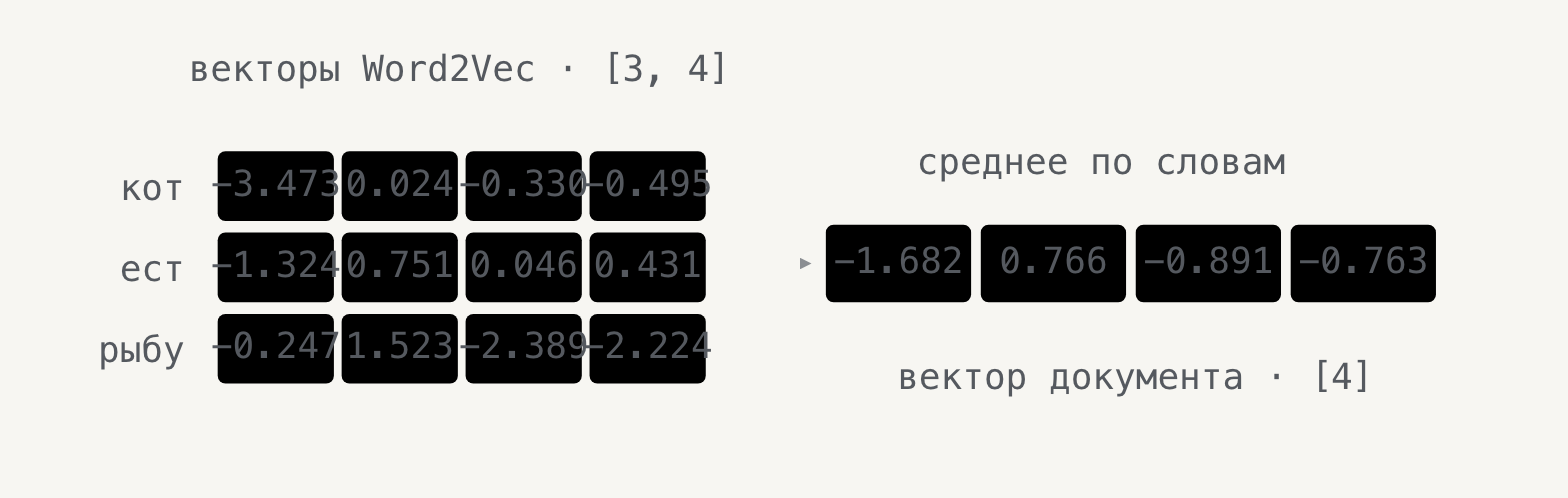

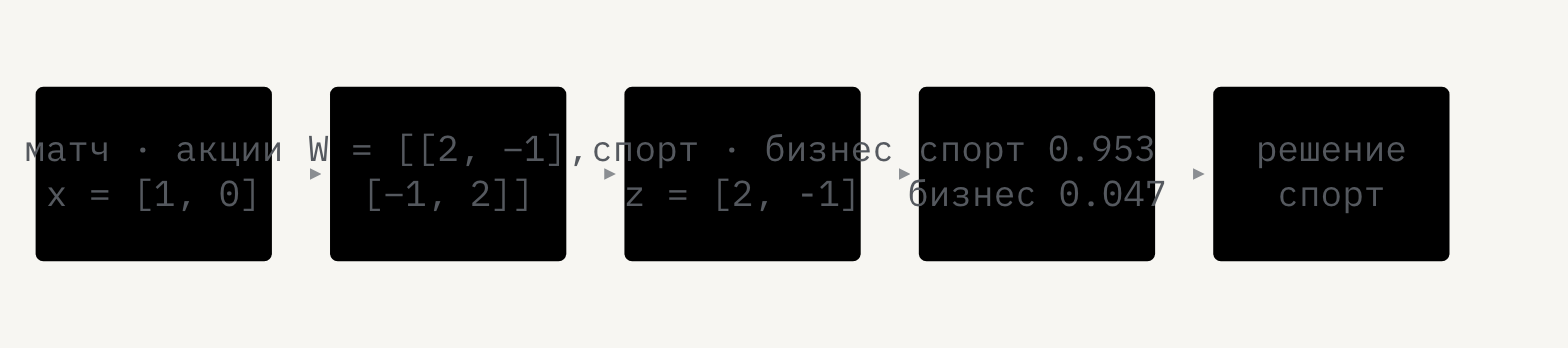

In [ ]:
news_train = pd.DataFrame(DATA["news_train"])
news_test = pd.DataFrame(DATA["news_test"])

# Одинаковые тексты не должны попасть в разные части.
news_train = news_train.drop_duplicates("text").reset_index(drop=True)
news_test = news_test.drop_duplicates("text")
news_test = news_test[~news_test.text.isin(news_train.text)]
train_news, valid_news = train_test_split(
    news_train, train_size=2400, test_size=600, random_state=SEED,
    stratify=news_train.label)
_, test_news = train_test_split(
    news_test, test_size=600, random_state=SEED, stratify=news_test.label)
CLASS_NAMES = ["мир", "спорт", "бизнес", "наука и технологии"]
print("Обучение / проверка / тест:", len(train_news), len(valid_news), len(test_news))
print(train_news.groupby("label").size())

Обучение / проверка / тест: 2400 600 600
label
0    600
1    600
2    600
3    600
dtype: int64


In [4]:
baseline = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=300))
baseline.fit(train_news.text, train_news.label)
print("TF-IDF, accuracy на проверочной части:",
      accuracy_score(valid_news.label, baseline.predict(valid_news.text)))

TF-IDF, accuracy на проверочной части: 0.855


### Словарь, PAD и батч

Словарь строим только по обучающим текстам. PAD имеет индекс 0, UNK — 1. Слова вне словаря превращаются в UNK. Здесь используем простую токенизацию слов и пунктуации; она не реализует BPE.

Предельную длину берём по квантилю длин обучающих текстов. Длинные новости обрезаем; число таких новостей выводим. Внутри батча дополняем до длины самого длинного текста. PAD участвует в хранении батча, но исключается из усреднения.

In [5]:
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPECIALS = ["[PAD]", "[UNK]", "[BOS]", "[EOS]"]

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text).lower())

def build_vocab(texts, limit):
    counts = Counter(token for text in texts for token in tokenize(text))
    return {token: i for i, token in enumerate(SPECIALS +
            [word for word, _ in counts.most_common(limit - len(SPECIALS))
             if word not in SPECIALS])}

def encode(text, vocab, max_tokens):
    tokens = tokenize(text)[:max_tokens]
    return [vocab.get(token, UNK) for token in tokens] or [UNK]

news_vocab = build_vocab(train_news.text, limit=6000)
news_lengths = np.array([len(tokenize(text)) for text in train_news.text])
news_cap = max(1, int(np.quantile(news_lengths, .999, method="higher")))
print("Словарь:", len(news_vocab), "предел длины:", news_cap,
      "обрезанных обучающих текстов:", int((news_lengths > news_cap).sum()))

def news_rows(frame):
    return [(torch.tensor(encode(row.text, news_vocab, news_cap)), int(row.label))
            for row in frame.itertuples()]

def collate_news(rows):
    ids, labels = zip(*rows)
    return pad_sequence(ids, batch_first=True, padding_value=PAD), torch.tensor(labels)

def news_loader(frame, shuffle=False):
    return DataLoader(news_rows(frame), batch_size=32, shuffle=shuffle,
                      collate_fn=collate_news,
                      generator=torch.Generator().manual_seed(SEED))

news_train_loader = news_loader(train_news, True)
news_valid_loader = news_loader(valid_news)
news_test_loader = news_loader(test_news)
ids, labels = next(iter(news_train_loader))
print("Вход:", tuple(ids.shape), "цель:", tuple(labels.shape))
print("Маска первой новости:", (ids[0] != PAD).int().tolist())

Словарь: 6000 предел длины: 207 обрезанных обучающих текстов: 2
Вход: (32, 76) цель: (32,)
Маска первой новости: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### Векторы слов: skip-gram своими руками

Эмбеддинги можно обучить отдельно от классификатора и без меток. Skip-Gram из занятия 1 по центральному слову предсказывает соседей в окне. Пары «центр — сосед» берём из тех же 2400 обучающих новостей; служебные токены пропускаем. Negative sampling: к каждой настоящей паре добавляем `negative_count` случайных слов с меткой 0, модель учится отличать соседа из текста от случайного слова. Случайные слова выбираем с вероятностью, пропорциональной частоте в степени 0.75. Пары с частыми центрами вроде «the» прореживаем.

После обучения забираем таблицу `word_embeddings`: строка — вектор слова того же словаря, что у классификатора.

**До запуска:** у каких слов соседи окажутся осмысленными — у частых или у редких? Хватит ли 2400 новостей?

In [ ]:
def skipgram_pairs(texts, window=4):
    pairs = []
    for text in texts:
        ids = [i for i in encode(text, news_vocab, news_cap) if i >= len(SPECIALS)]
        for center, word in enumerate(ids):
            for j in range(max(0, center - window), min(len(ids), center + window + 1)):
                if j != center:
                    pairs.append((word, ids[j]))
    return torch.tensor(pairs)


In [ ]:

class SkipGram(nn.Module):
    def __init__(self, vocab_size, d=48):
        super().__init__()
        self.word_embeddings = nn.Embedding(vocab_size, d)      # их заберём в классификатор
        self.context_embeddings = nn.Embedding(vocab_size, d)

    def forward(self, center_ids, candidates):
        centers = self.word_embeddings(center_ids)              # B × d
        contexts = self.context_embeddings(candidates)          # B × (1 + k) × d
        return (centers[:, None, :] * contexts).sum(-1)         # B × (1 + k)


In [ ]:

pairs = skipgram_pairs(train_news.text)
counts = torch.bincount(pairs[:, 0], minlength=len(news_vocab)).float()
sampling_probs = counts ** .75 / (counts ** .75).sum()
keep_probs = (1e-3 / (counts / counts.sum())).sqrt().clamp(max=1)   # прореживание частых слов
print("Пар центр — сосед:", len(pairs))


In [ ]:

negative_count = 5
torch.manual_seed(SEED)
skipgram = SkipGram(len(news_vocab)).to(device)
optimizer = torch.optim.Adam(skipgram.parameters(), lr=.01)
for epoch in range(5):
    started = time.perf_counter()
    kept = pairs[torch.rand(len(pairs)) < keep_probs[pairs[:, 0]]]
    loss_sum = 0.
    for batch in torch.randperm(len(kept)).split(512):
        center_ids, context_ids = kept[batch, 0], kept[batch, 1]
        negatives = torch.multinomial(sampling_probs, len(batch) * negative_count,
                                      replacement=True).reshape(-1, negative_count)
        candidates = torch.cat([context_ids[:, None], negatives], dim=1)
        labels = torch.zeros_like(candidates, dtype=torch.float)
        labels[:, 0] = 1
        loss = F.binary_cross_entropy_with_logits(skipgram(center_ids, candidates), labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(batch)
    print(f"Эпоха {epoch + 1}: loss={loss_sum / len(kept):.3f}; пар {len(kept)}; "
          f"{time.perf_counter() - started:.1f} с", flush=True)
own_vectors = skipgram.word_embeddings.weight.detach().cpu()

In [ ]:
id_to_word = {i: word for word, i in news_vocab.items()}
word_counts = Counter(token for text in train_news.text for token in tokenize(text))

def neighbours(vectors, word, n=6):
    normed = F.normalize(vectors, dim=1)
    similarity = normed @ normed[news_vocab[word]]
    similarity[:len(SPECIALS)] = -1                      # служебные токены не показываем
    return [id_to_word[int(i)] for i in similarity.topk(n + 1).indices[1:]]

PROBE_WORDS = ["oil", "iraq", "microsoft", "football", "nasa", "hurricane", "soccer"]
for word in PROBE_WORDS:
    print(f"{word} ({word_counts[word]} раз):", ", ".join(neighbours(own_vectors, word)))
seen = np.array([word_counts[word] for word in news_vocab if word not in SPECIALS])
print(f"Слов словаря, встреченных в обучении меньше 5 раз: {(seen < 5).mean():.0%}")

### Как ложатся слова

Возьмём по 12 самых сильных признаков каждой темы из TF-IDF-модели, без стоп-слов, и спроецируем их векторы на плоскость методом главных компонент. Цвет — тема, за которую слово голосует в TF-IDF-модели. В заголовке — доля соседей той же темы: для каждого слова берём 5 ближайших по косинусу среди этих 48 слов в исходном пространстве, без проекции. У векторов, не связанных с темой, она около четверти.

Слова берём двух видов: частые, встреченные в обучающих новостях не меньше 30 раз, и редкие — от 5 до 15 раз. Слева — случайные векторы, с которых начинается обучение.

**До запуска:** для каких слов темы разойдутся? Хватит ли 2400 новостей?

In [ ]:
tfidf, logreg = baseline[0], baseline[-1]
feature_names = tfidf.get_feature_names_out()

def topic_words(min_count, max_count=math.inf, per_topic=12):
    """Самые сильные признаки каждой темы в TF-IDF-модели с заданной частотой в обучении."""
    words, taken = [], set()
    for label in range(4):
        strongest = [feature_names[j] for j in logreg.coef_[label].argsort()[::-1]]
        chosen = [word for word in strongest
                  if word in news_vocab and word.isalpha() and word not in ENGLISH_STOP_WORDS
                  and word not in taken and min_count <= word_counts[word] <= max_count][:per_topic]
        taken.update(chosen)
        words += [(word, label) for word in chosen]
    return words

def same_topic_share(matrix, labels, k=5):
    normed = matrix / np.linalg.norm(matrix, axis=1, keepdims=True)
    similarity = normed @ normed.T
    np.fill_diagonal(similarity, -np.inf)
    nearest = np.argsort(-similarity, axis=1)[:, :k]
    return (labels[nearest] == labels[:, None]).mean()

def plot_words(panels):
    fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 5.5))
    for ax, (title, vectors, words) in zip(axes, panels):
        matrix = np.stack([np.asarray(vectors[news_vocab[word]]) for word, _ in words])
        labels = np.array([label for _, label in words])
        points = PCA(2, random_state=SEED).fit_transform(matrix)
        for label, color in zip(range(4), ["tab:blue", "tab:orange", "tab:green", "tab:purple"]):
            rows = np.flatnonzero(labels == label)
            ax.scatter(points[rows, 0], points[rows, 1], color=color, label=CLASS_NAMES[label])
            for row in rows:
                ax.annotate(words[row][0], points[row], fontsize=8, color=color,
                            xytext=(3, 2), textcoords="offset points")
        ax.set_title(f"{title}\nсоседи той же темы: {same_topic_share(matrix, labels):.0%}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    axes[0].legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()

frequent_words, rare_words = topic_words(30), topic_words(5, 15)
torch.manual_seed(SEED)
random_vectors = nn.Embedding(len(news_vocab), 48).weight.detach()
plot_words([("случайные векторы, частые слова", random_vectors, frequent_words),
            ("skip-gram, частые слова (от 30 раз)", own_vectors, frequent_words),
            ("skip-gram, редкие слова (5–15 раз)", own_vectors, rare_words)])

In [6]:
class MeanClassifier(nn.Module):
    def __init__(self, vocab_size, d=48, classes=4, vectors=None, freeze=False):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d, padding_idx=PAD)
        if vectors is not None:                          # готовые векторы слов
            self.embedding.weight.data.copy_(vectors)
            self.embedding.weight.requires_grad_(not freeze)
        self.head = nn.Linear(d, classes)

    def forward(self, ids):
        vectors = self.embedding(ids)                    # B × T × d
        mask = (ids != PAD).unsqueeze(-1)                # B × T × 1
        pooled = (vectors * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        return self.head(pooled)                         # B × C

classifier = MeanClassifier(len(news_vocab)).to(device)
print("Оценки классов:", tuple(classifier(ids).shape))

Оценки классов: (32, 4)


### Обучение

`cross_entropy` получает оценки классов до softmax и индексы правильных меток. На обучении считаем градиенты и меняем веса. На проверке вызываем `eval()` и отключаем градиенты. Выбираем состояние по проверочной части; тест оставляем для итоговой оценки.

In [7]:
@torch.no_grad()
def classification_scores(model, loader):
    model.eval()
    targets, predictions = [], []
    for ids, labels in loader:
        predictions.extend(model(ids.to(device)).argmax(-1).cpu().tolist())
        targets.extend(labels.tolist())
    return accuracy_score(targets, predictions), targets, predictions

def train_classifier(model, epochs=10, lr=.003):
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    best_accuracy, best_state = -1, None
    for epoch in range(epochs):
        started = time.perf_counter()
        model.train()
        loss_sum, examples = 0., 0
        for ids, labels in news_train_loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(ids), labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(labels)
            examples += len(labels)
        accuracy, _, _ = classification_scores(model, news_valid_loader)
        if accuracy > best_accuracy:
            best_accuracy, best_state = accuracy, copy.deepcopy(model.state_dict())
        print(f"Эпоха {epoch + 1}: loss={loss_sum / examples:.3f}; "
              f"проверочная accuracy={accuracy:.3f}; {time.perf_counter() - started:.1f} с", flush=True)
    model.load_state_dict(best_state)

train_classifier(classifier)


Эпоха 1: loss=1.342; проверочная accuracy=0.555; 0.1 с
Эпоха 2: loss=1.160; проверочная accuracy=0.672; 0.0 с
Эпоха 3: loss=0.857; проверочная accuracy=0.745; 0.0 с


In [8]:
test_accuracy, targets, predictions = classification_scores(classifier, news_test_loader)
print("Тест TF-IDF:", accuracy_score(test_news.label, baseline.predict(test_news.text)))
print("Тест нейросети:", test_accuracy)
print(classification_report(targets, predictions, labels=list(range(4)),
                            target_names=CLASS_NAMES, zero_division=0))

@torch.no_grad()
def classify(text):
    classifier.eval()
    ids = torch.tensor([encode(text, news_vocab, news_cap)], device=device)
    probabilities = classifier(ids).softmax(-1)[0].cpu()
    return {name: round(float(p), 3) for name, p in zip(CLASS_NAMES, probabilities)}

print(classify("The team won the final match of the season."))
# Проверяем, что добавление PAD не меняет предсказание.
classifier.eval()
probe = torch.tensor([[4, 5, 6]])
with torch.no_grad():
    torch.testing.assert_close(classifier(probe), classifier(F.pad(probe, (0, 5), value=PAD)))
print("PAD не меняет результат усреднения.")

Тест TF-IDF: 0.8416666666666667
Тест нейросети: 0.7566666666666667
                    precision    recall  f1-score   support

               мир       0.78      0.75      0.76       150
             спорт       0.77      0.90      0.83       150
            бизнес       0.83      0.57      0.68       150
наука и технологии       0.68      0.81      0.74       150

          accuracy                           0.76       600
         macro avg       0.77      0.76      0.75       600
      weighted avg       0.77      0.76      0.75       600

{'мир': 0.004, 'спорт': 0.988, 'бизнес': 0.005, 'наука и технологии': 0.003}
PAD не меняет результат усреднения.


In [ ]:
# Те же векторы skip-gram в классификаторе: таблицу не меняем, учим только линейный слой.
torch.manual_seed(SEED)
own_classifier = MeanClassifier(len(news_vocab), vectors=own_vectors, freeze=True).to(device)
train_classifier(own_classifier)

### Готовые векторы из gensim

Векторы не обязательно обучать самим. `gensim.downloader` хранит уже обученные таблицы. Возьмём `glove-wiki-gigaword-100`: GloVe (Pennington et al., 2014), обученный на Википедии и новостном корпусе Gigaword, около 6 млрд токенов; 400 тысяч слов в нижнем регистре, 100 чисел на слово, архив 128 МБ. Это не word2vec: GloVe учится по матрице совместной встречаемости слов, а не предсказанием соседей в окне. Для классификатора важно другое — векторы готовы, их достаточно прочитать.

Словарь GloVe, как и наша токенизация, в нижнем регистре. Слова, которых нет в GloVe, получают малый случайный вектор; их долю выводим.

**До запуска:** что станет с соседями редких слов и с картинкой тем? Придётся ли дообучать эти векторы для классификатора?

In [ ]:
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-100")   # 128 МБ, скачивается один раз

generator = torch.Generator().manual_seed(SEED)
pretrained = torch.randn(len(news_vocab), glove.vector_size, generator=generator) * .01
found = 0
for word, i in news_vocab.items():
    if word in glove and word not in SPECIALS:
        pretrained[i] = torch.from_numpy(glove[word].copy())
        found += 1
print(f"Слов словаря с вектором GloVe: {found / (len(news_vocab) - len(SPECIALS)):.0%}")
for word in PROBE_WORDS:
    print(f"{word} ({word_counts[word]} раз):", ", ".join(neighbours(pretrained, word)))

In [ ]:
plot_words([("skip-gram, редкие слова (5–15 раз)", own_vectors, rare_words),
            ("GloVe, те же слова", pretrained, rare_words)])

In [ ]:
torch.manual_seed(SEED)
pretrained_classifier = MeanClassifier(len(news_vocab), d=glove.vector_size,
                                       vectors=pretrained, freeze=True).to(device)
train_classifier(pretrained_classifier)

results = [{"модель": "TF-IDF + логистическая регрессия", "обучаемых параметров": "—",
            "проверка": accuracy_score(valid_news.label, baseline.predict(valid_news.text)),
            "тест": accuracy_score(test_news.label, baseline.predict(test_news.text))}]
for name, model in [("эмбеддинги с нуля", classifier),
                    ("skip-gram, векторы заморожены", own_classifier),
                    ("GloVe, векторы заморожены", pretrained_classifier)]:
    results.append({"модель": name,
                    "обучаемых параметров": sum(p.numel() for p in model.parameters() if p.requires_grad),
                    "проверка": classification_scores(model, news_valid_loader)[0],
                    "тест": classification_scores(model, news_test_loader)[0]})
pd.DataFrame(results).round(3)

**Разбор.** Skip-gram на 2400 новостях выучил частые слова: их соседи осмысленны, частые слова тем на плоскости расходятся. Половина словаря встретилась в обучении реже пяти раз; у редких слов соседи случайны, и редкие слова тем перемешаны. Классификатор поверх замороженных векторов skip-gram уступает эмбеддингам, обученным вместе с классификатором: тем эмбеддингам помогали метки. GloVe обучен на миллиардах токенов, поэтому осмысленные соседи есть и у редких слов. Линейный слой поверх его замороженной таблицы — несколько сотен обучаемых параметров вместо сотен тысяч — выходит на уровень TF-IDF. Все модели здесь теряют порядок слов: TF-IDF использует униграммы, нейросети — среднее векторов.

**Попробуйте:** переставьте слова, добавьте неизвестное слово, замените тему. Посмотрите ошибочные новости. Обучите skip-gram дольше или с другим окном; разморозьте векторы GloVe (`freeze=False`). Меняйте настройки по проверочной части; повторная настройка по тесту делает его частью разработки.

## 2. Генерация: одна цель на каждую позицию

Теперь метка — следующий токен. Используем ту же простую токенизацию. Для каждого анекдота добавляем BOS и EOS. Вход — последовательность без последнего токена, цель — та же последовательность без первого. На обучении правильный префикс уже известен: это teacher forcing.

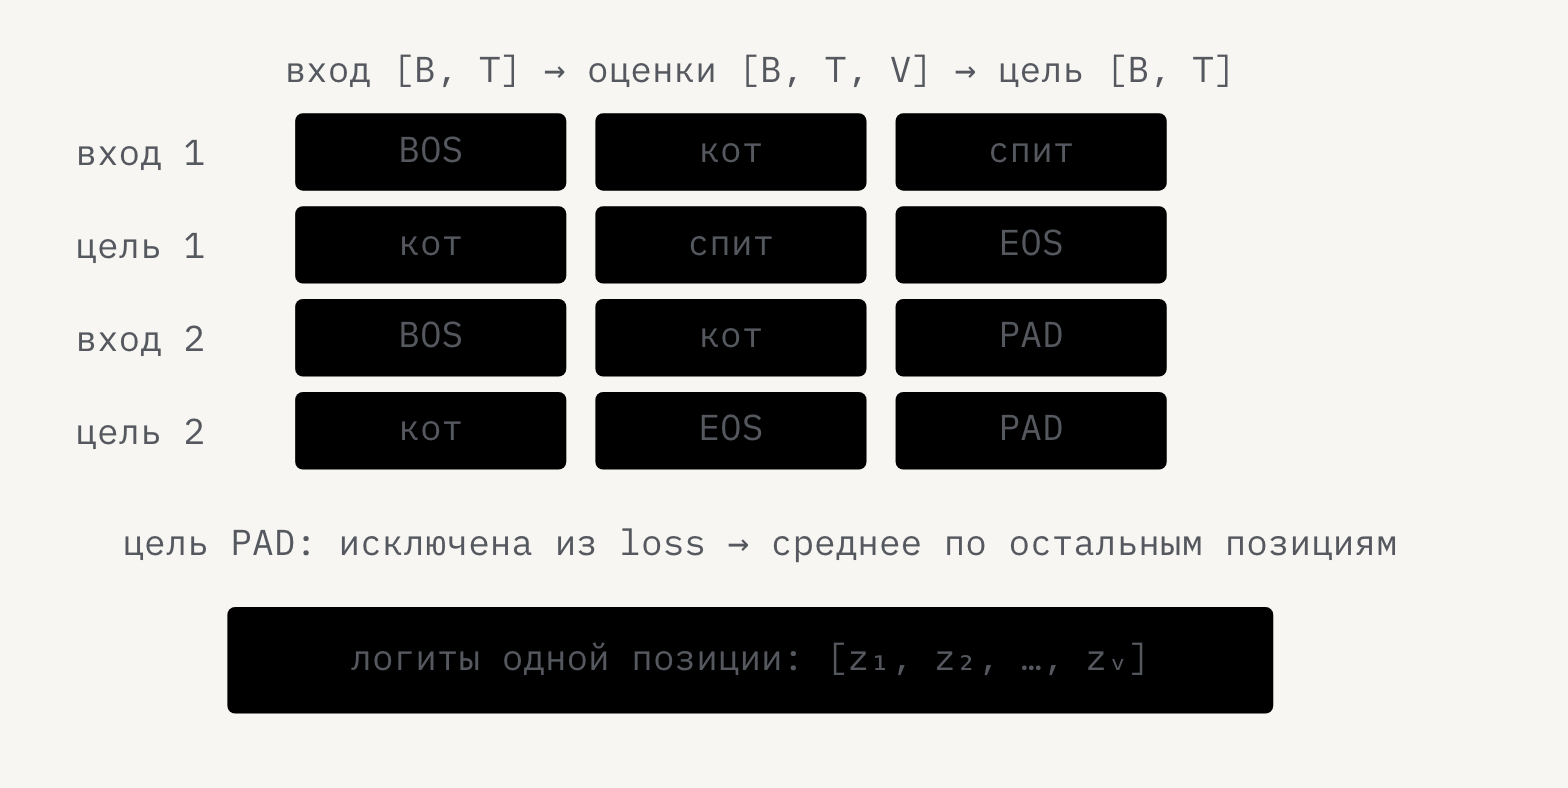

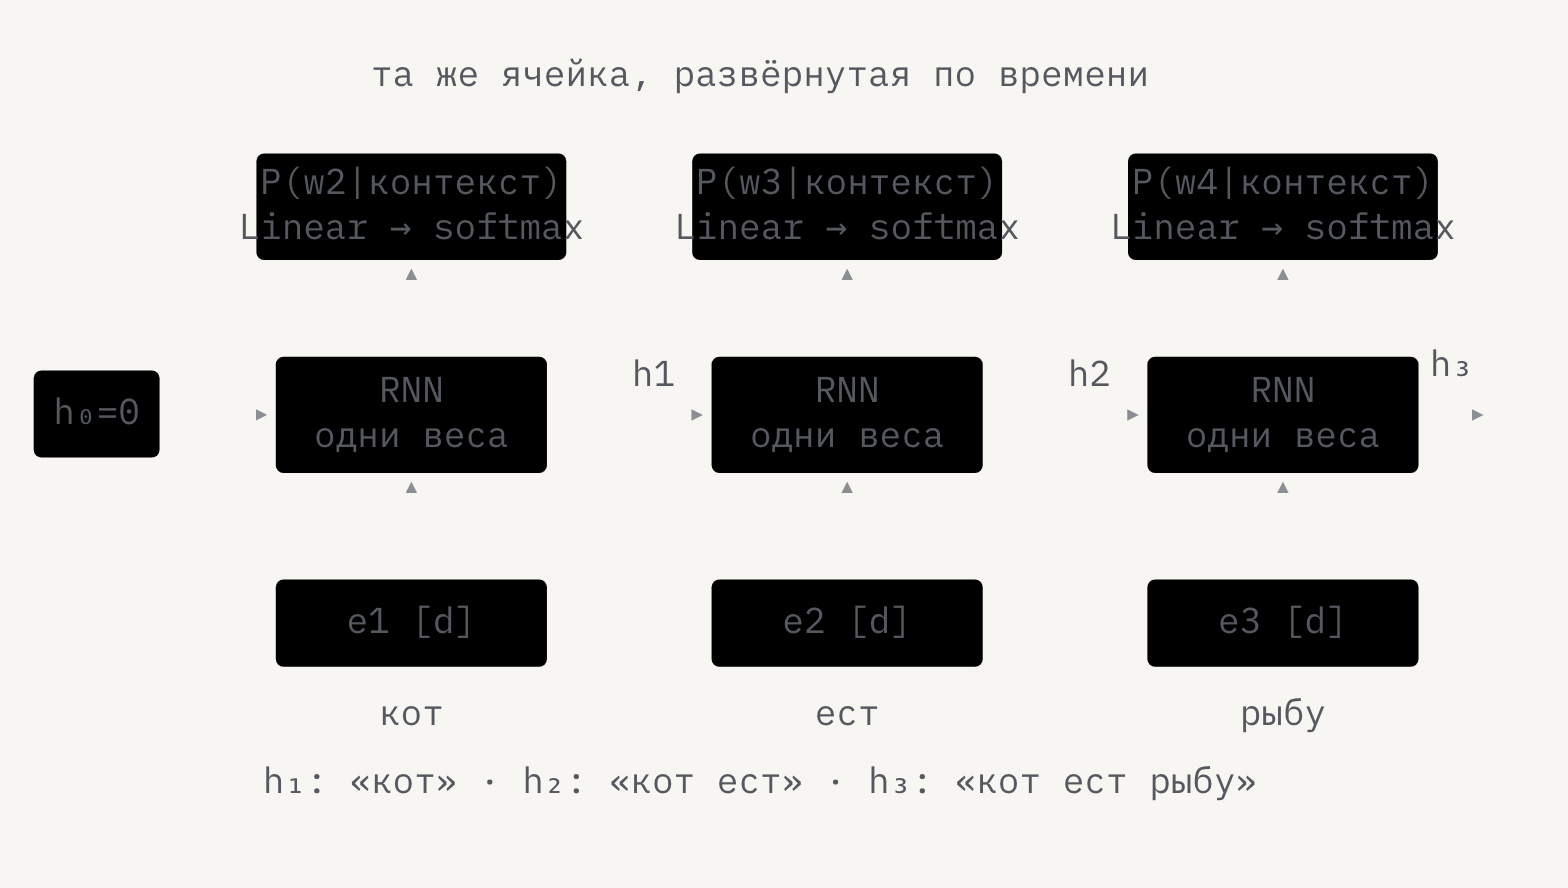

📌 **До запуска:** чем различаются число выходов и форма цели у классификатора и языковой модели? Что случится, если включить PAD в loss?

In [9]:
jokes = DATA["jokes"].copy()
rng = random.Random(SEED)
rng.shuffle(jokes)
lm_train, lm_valid, lm_test = jokes[:480], jokes[480:540], jokes[540:]
del jokes
lm_vocab = build_vocab(lm_train, limit=2000)
id_to_token = {i: token for token, i in lm_vocab.items()}
lm_lengths = np.array([len(tokenize(text)) for text in lm_train])
lm_cap = int(np.quantile(lm_lengths, .999, method="higher"))
print("Обучение / проверка / тест:", len(lm_train), len(lm_valid), len(lm_test))
print("Словарь:", len(lm_vocab), "предел длины:", lm_cap,
      "обрезанных обучающих текстов:", int((lm_lengths > lm_cap).sum()))

def lm_rows(texts):
    return [torch.tensor([BOS] + encode(text, lm_vocab, lm_cap) + [EOS]) for text in texts]

def collate_lm(rows):
    batch = pad_sequence(rows, batch_first=True, padding_value=PAD)
    return batch[:, :-1], batch[:, 1:]

def lm_loader(texts, shuffle=False):
    return DataLoader(lm_rows(texts), batch_size=16, shuffle=shuffle,
                      collate_fn=collate_lm,
                      generator=torch.Generator().manual_seed(SEED))

lm_valid_loader, lm_test_loader = lm_loader(lm_valid), lm_loader(lm_test)
inputs, targets = next(iter(lm_loader(lm_train)))
for name, texts in [("обучение", lm_train), ("проверка", lm_valid), ("тест", lm_test)]:
    tokens = [i for row in lm_rows(texts) for i in row.tolist()[1:-1]]
    print(f"Доля UNK, {name}: {sum(i == UNK for i in tokens) / len(tokens):.1%}")
print("Вход / цель:", tuple(inputs.shape), tuple(targets.shape))
print("Вход:", [id_to_token[int(i)] for i in inputs[0, :12]])
print("Цель:", [id_to_token[int(i)] for i in targets[0, :12]])

Обучение / проверка / тест: 480 60 60
Словарь: 2000 предел длины: 63 обрезанных обучающих текстов: 0
Доля UNK, обучение: 16.7%
Доля UNK, проверка: 31.8%
Доля UNK, тест: 31.0%
Вход / цель: (16, 60) (16, 60)
Вход: ['[BOS]', 'никогда', 'не', 'покупаю', 'шаурму', 'в', 'ларьках', ',', 'делаю', 'дома', ',', 'получается']
Цель: ['никогда', 'не', 'покупаю', 'шаурму', 'в', 'ларьках', ',', 'делаю', 'дома', ',', 'получается', 'как']


### GRU: контекст в состоянии

Эмбеддинги подаются в GRU. На каждой позиции выходной линейный слой получает состояние и возвращает оценки словаря. При дополнении справа PAD находится после всех полезных токенов, поэтому не влияет на их состояния; соответствующие целевые позиции исключаем из loss.

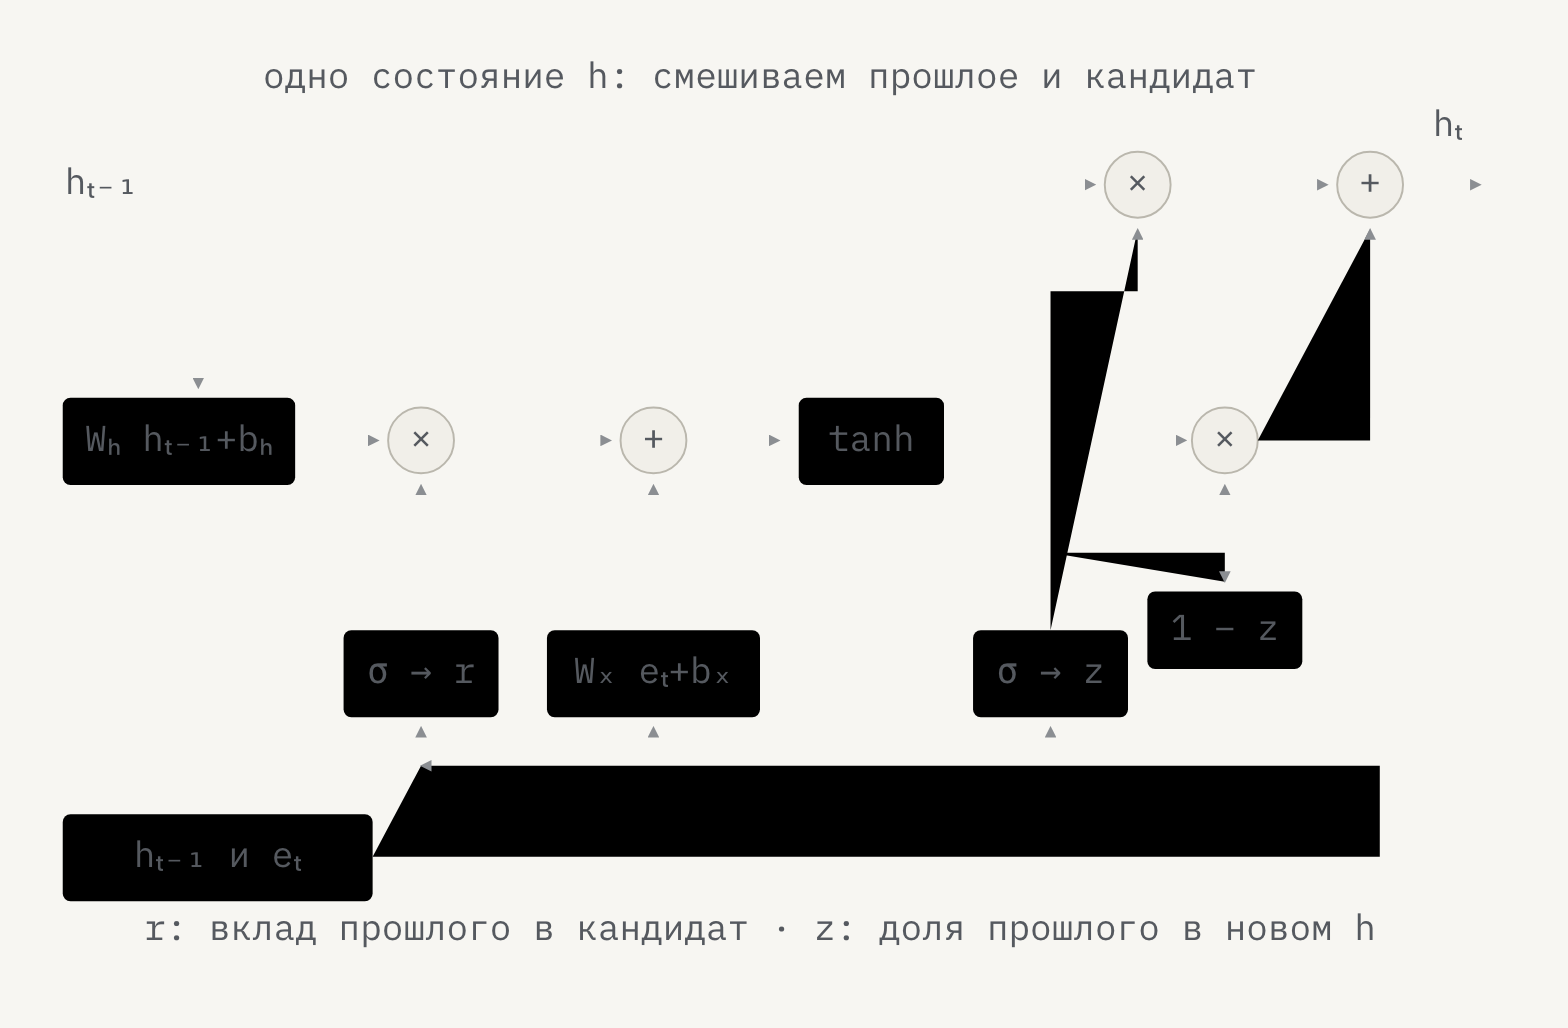

In [10]:
class GRULanguageModel(nn.Module):
    def __init__(self, vocab_size, d=48):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d, padding_idx=PAD)
        self.gru = nn.GRU(d, d, batch_first=True)
        self.head = nn.Linear(d, vocab_size)

    def forward(self, ids):
        states, _ = self.gru(self.embedding(ids))
        return self.head(states)                         # B × T × V

    def next_logits(self, ids):
        states, _ = self.gru(self.embedding(ids))
        return self.head(states[:, -1])                  # B × V

gru = GRULanguageModel(len(lm_vocab)).to(device)
print("Оценки токенов:", tuple(gru(inputs[:2]).shape))

Оценки токенов: (2, 60, 2000)


### Loss и перплексия

Суммируем ошибки по всем целевым токенам, кроме PAD, и делим на их число. Для проверки суммируем по всему корпусу: среднее средних по батчам дало бы неодинаковый вес токенам.

$$L = -\frac{1}{N}\sum_{i=1}^{N}\ln P(y_i\mid y_{<i}),\qquad \mathrm{PPL}=\exp(L).$$

Перплексию сравниваем при одинаковых данных, словаре, токенизации и обработке EOS/UNK. Наш маленький словарь заменяет многие слова на UNK: низкая PPL сама по себе не гарантирует хороших текстов.

In [11]:
def token_loss(logits, targets, reduction="mean"):
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1),
                           ignore_index=PAD, reduction=reduction)

@torch.no_grad()
def language_scores(model, loader):
    model.eval()
    total_loss, token_count = 0., 0
    for ids, targets in loader:
        ids, targets = ids.to(device), targets.to(device)
        total_loss += float(token_loss(model(ids), targets, "sum"))
        token_count += int((targets != PAD).sum())
    loss = total_loss / token_count
    return loss, math.exp(loss)

def train_language_model(model, epochs=2):
    optimizer = torch.optim.Adam(model.parameters(), lr=.003)
    best_loss, best_state = float("inf"), None
    for epoch in range(epochs):
        started = time.perf_counter()
        model.train()
        total_loss, token_count = 0., 0
        loader = lm_loader(lm_train, shuffle=True)
        for step, (ids, targets) in enumerate(loader, 1):
            ids, targets = ids.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = token_loss(model(ids), targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            count = int((targets != PAD).sum())
            total_loss += float(loss.detach()) * count
            token_count += count
            elapsed = time.perf_counter() - started
            print(f"\rЭпоха {epoch+1}: {step}/{len(loader)}, "
                  f"{step / elapsed:.1f} батч/с, ETA {elapsed / step * (len(loader)-step):.0f} с",
                  end="", flush=True)
        valid_loss, valid_ppl = language_scores(model, lm_valid_loader)
        if valid_loss < best_loss:
            best_loss, best_state = valid_loss, copy.deepcopy(model.state_dict())
        print(f"\nОбучение loss={total_loss / token_count:.3f}; "
              f"проверка loss={valid_loss:.3f}, PPL={valid_ppl:.2f}; "
              f"{time.perf_counter() - started:.1f} с", flush=True)
    model.load_state_dict(best_state)

train_language_model(gru)

Эпоха 1: 30/30, 146.8 батч/с, ETA 0 с
Обучение loss=6.326; проверка loss=4.002, PPL=54.68; 0.2 с
Эпоха 2: 30/30, 169.5 батч/с, ETA 0 с
Обучение loss=5.026; проверка loss=3.874, PPL=48.16; 0.2 с


### Генерация: возвращаем выбранный токен во вход

При генерации эталонного продолжения нет. На каждом шаге модель получает префикс, мы берём оценки последней позиции, делим на температуру и выбираем следующий токен из softmax. Останавливаемся на EOS или предельном числе новых токенов.

Для ясности пересчитываем весь префикс на каждом шаге. GRU можно ускорить, сохраняя состояние между шагами; здесь один интерфейс генерации для обеих языковых моделей.

In [12]:
@torch.no_grad()
def generate(model, prefix="", temperature=.8, max_new_tokens=40, seed=SEED):
    if temperature <= 0:
        raise ValueError("Температура должна быть положительной")
    model.eval()
    ids = [BOS] + ([lm_vocab.get(t, UNK) for t in tokenize(prefix)] if prefix else [])
    generator = torch.Generator(device=device).manual_seed(seed)
    for _ in range(max_new_tokens):
        scores = model.next_logits(torch.tensor([ids], device=device))[0].clone()
        scores[[PAD, BOS]] = -torch.inf
        probabilities = (scores / temperature).softmax(-1)
        next_id = int(torch.multinomial(probabilities, 1, generator=generator))
        ids.append(next_id)
        if next_id == EOS:
            break
    return " ".join(id_to_token[i] for i in ids[1:] if i != EOS)

print("Тест GRU, loss и PPL:", language_scores(gru, lm_test_loader))
for temperature in [.5, 1.]:
    print("T =", temperature, generate(gru, prefix="я", temperature=temperature))

Тест GRU, loss и PPL: (3.9485160186110146, 51.85835287479346)
T = 0.5 я [UNK] [UNK] [UNK] [UNK] [UNK] , - [UNK] - [UNK] , [UNK] [UNK] [UNK] [UNK] .
T = 1.0 я [UNK] одну сначала меня еще , мужчин [UNK] - [UNK] , не орать - раз .


**Разбор.** На этой маленькой выборке тексты могут быть бессвязными, а UNK — частым. Температура меняет распределение при выборе токена, но не обученные веса. Сравните несколько генераций с разными seed; один удачный пример не описывает качество модели.

**Проверьте:** почему softmax нужен в генерации, но не перед `cross_entropy`? Почему нельзя подать эталонное продолжение при оценке качества свободной генерации?

## 3. Блок трансформера своими руками

Начнём с одной головы. На входе Q, K, V и булева маска, где `True` означает разрешённую пару. Оси: B — батч, H — голова, T — запрос, S — ключ, dₖ — признак головы. Softmax идёт по S. В каждой строке должен остаться хотя бы один разрешённый ключ.

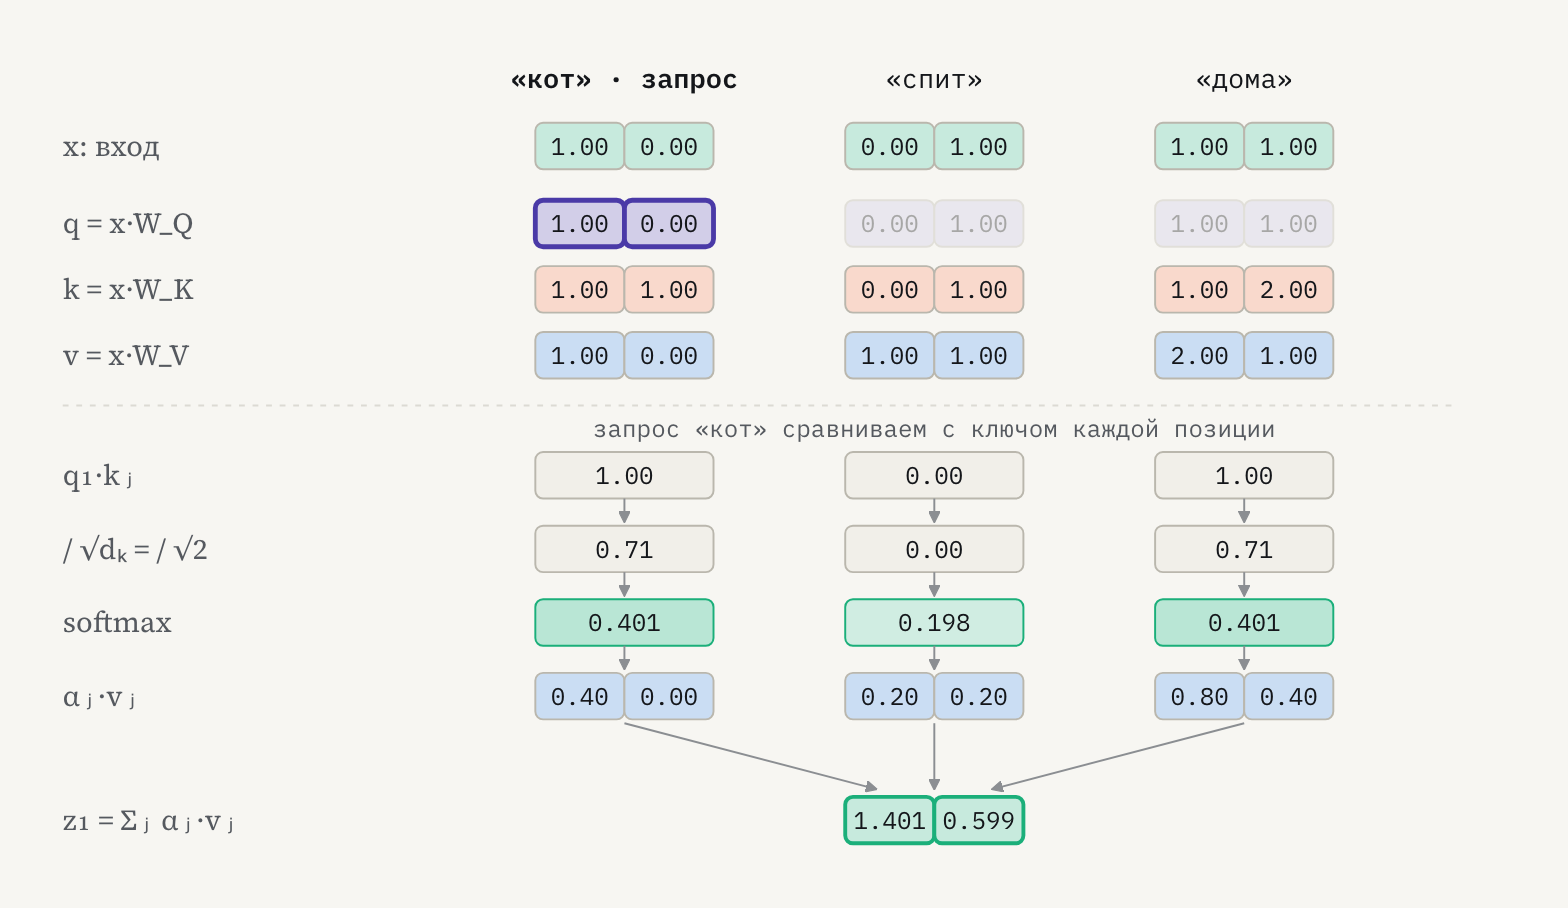

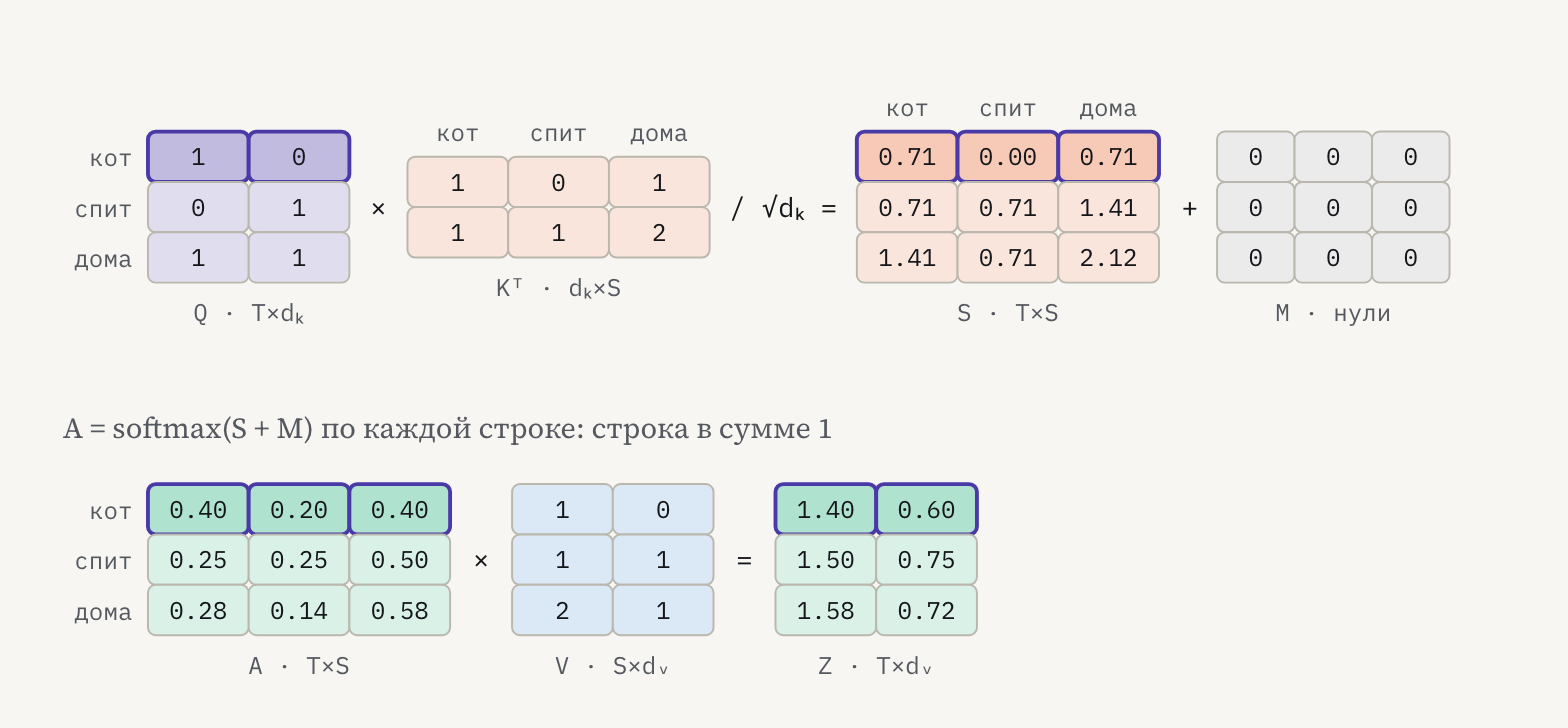

📌 **До запуска:** какие формы имеют матрица весов и выход? Что изменится при замене V, если сохранить Q и K?

In [13]:
def attention(q, k, v, allowed):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
    scores = scores.masked_fill(~allowed, -torch.inf)
    weights = scores.softmax(dim=-1)
    return weights @ v, weights

q = torch.randn(2, 3, 5, 8)
k, v = torch.randn_like(q), torch.randn_like(q)
allowed = torch.ones(5, 5, dtype=torch.bool).tril()
actual, weights = attention(q, k, v, allowed)
expected = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed)
torch.testing.assert_close(actual, expected, atol=1e-6, rtol=1e-5)
torch.testing.assert_close(weights.sum(-1), torch.ones(2, 3, 5))
assert torch.count_nonzero(weights.masked_select(~allowed)) == 0
print("Веса:", tuple(weights.shape), "выход:", tuple(actual.shape))
print("Расчёт совпал с PyTorch; закрытые позиции имеют нулевой вес.")

Веса: (2, 3, 5, 5) выход: (2, 3, 5, 8)
Расчёт совпал с PyTorch; закрытые позиции имеют нулевой вес.


### Несколько голов

Проецируем X в Q, K, V, разделяем признаки на H голов. Каждая голова читает все доступные позиции. После attention объединяем признаки и применяем выходную проекцию. `transpose` меняет оси; `reshape` после него собирает головы обратно.

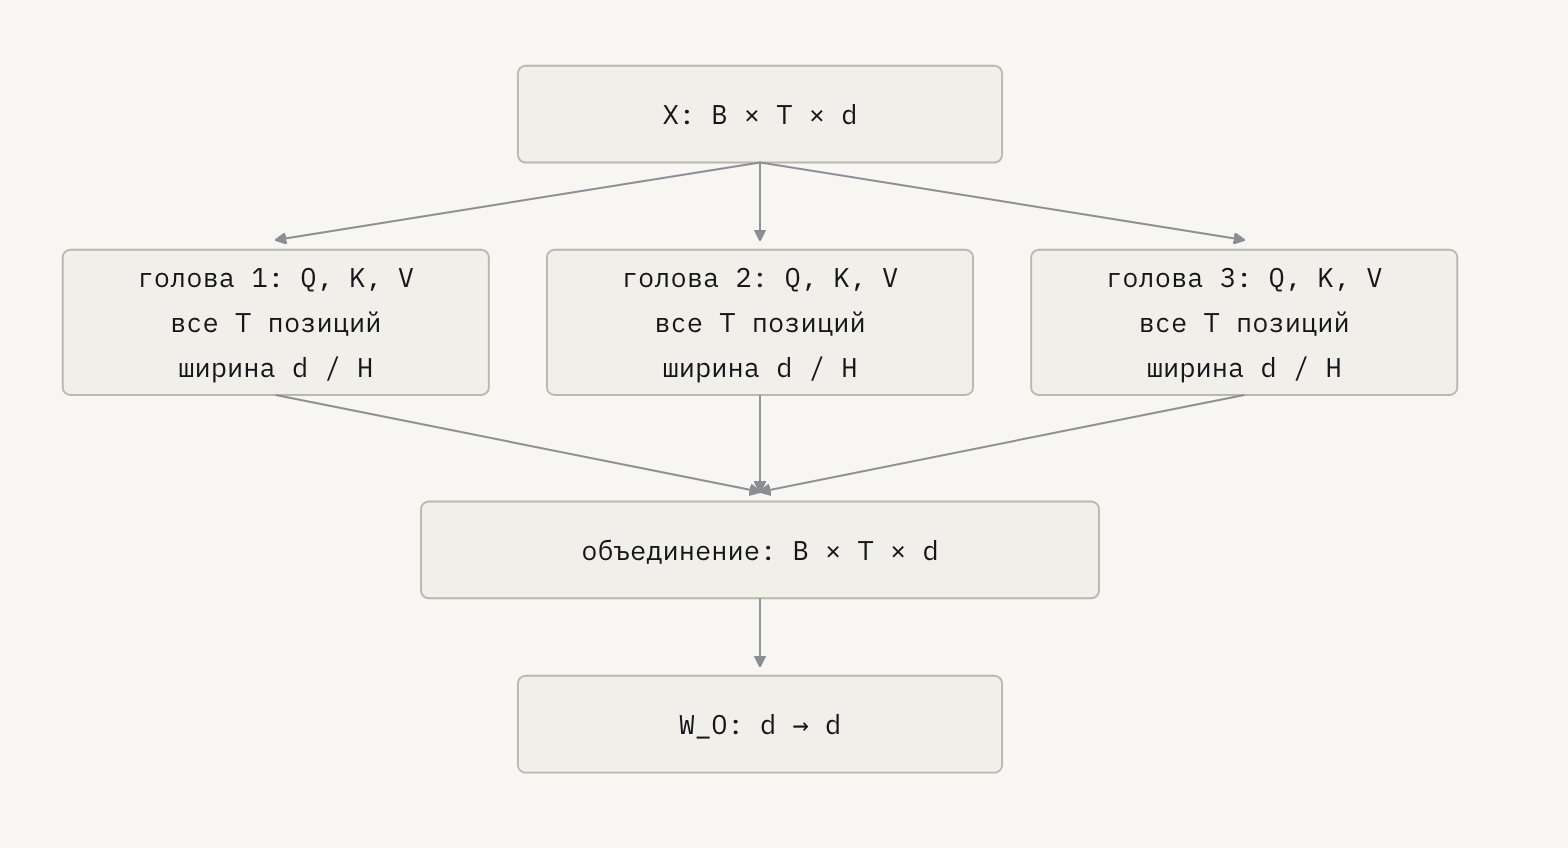

In [14]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        if d % heads:
            raise ValueError("Ширина модели должна делиться на число голов")
        self.heads = heads
        self.qkv = nn.Linear(d, 3 * d)
        self.output = nn.Linear(d, d)

    def forward(self, x, allowed):
        batch, length, d = x.shape
        qkv = self.qkv(x).reshape(batch, length, 3, self.heads, d // self.heads)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        result, _ = attention(q, k, v, allowed)
        joined = result.transpose(1, 2).reshape(batch, length, d)
        return self.output(joined)

### Причинный блок: нормализация, attention и FFN

Используем Pre-LN: нормализация до каждого подслоя. Residual сохраняет прямой путь входа через сложение. FFN применяется к каждой позиции отдельно, с одинаковыми весами. Dropout в этой учебной реализации опущен.

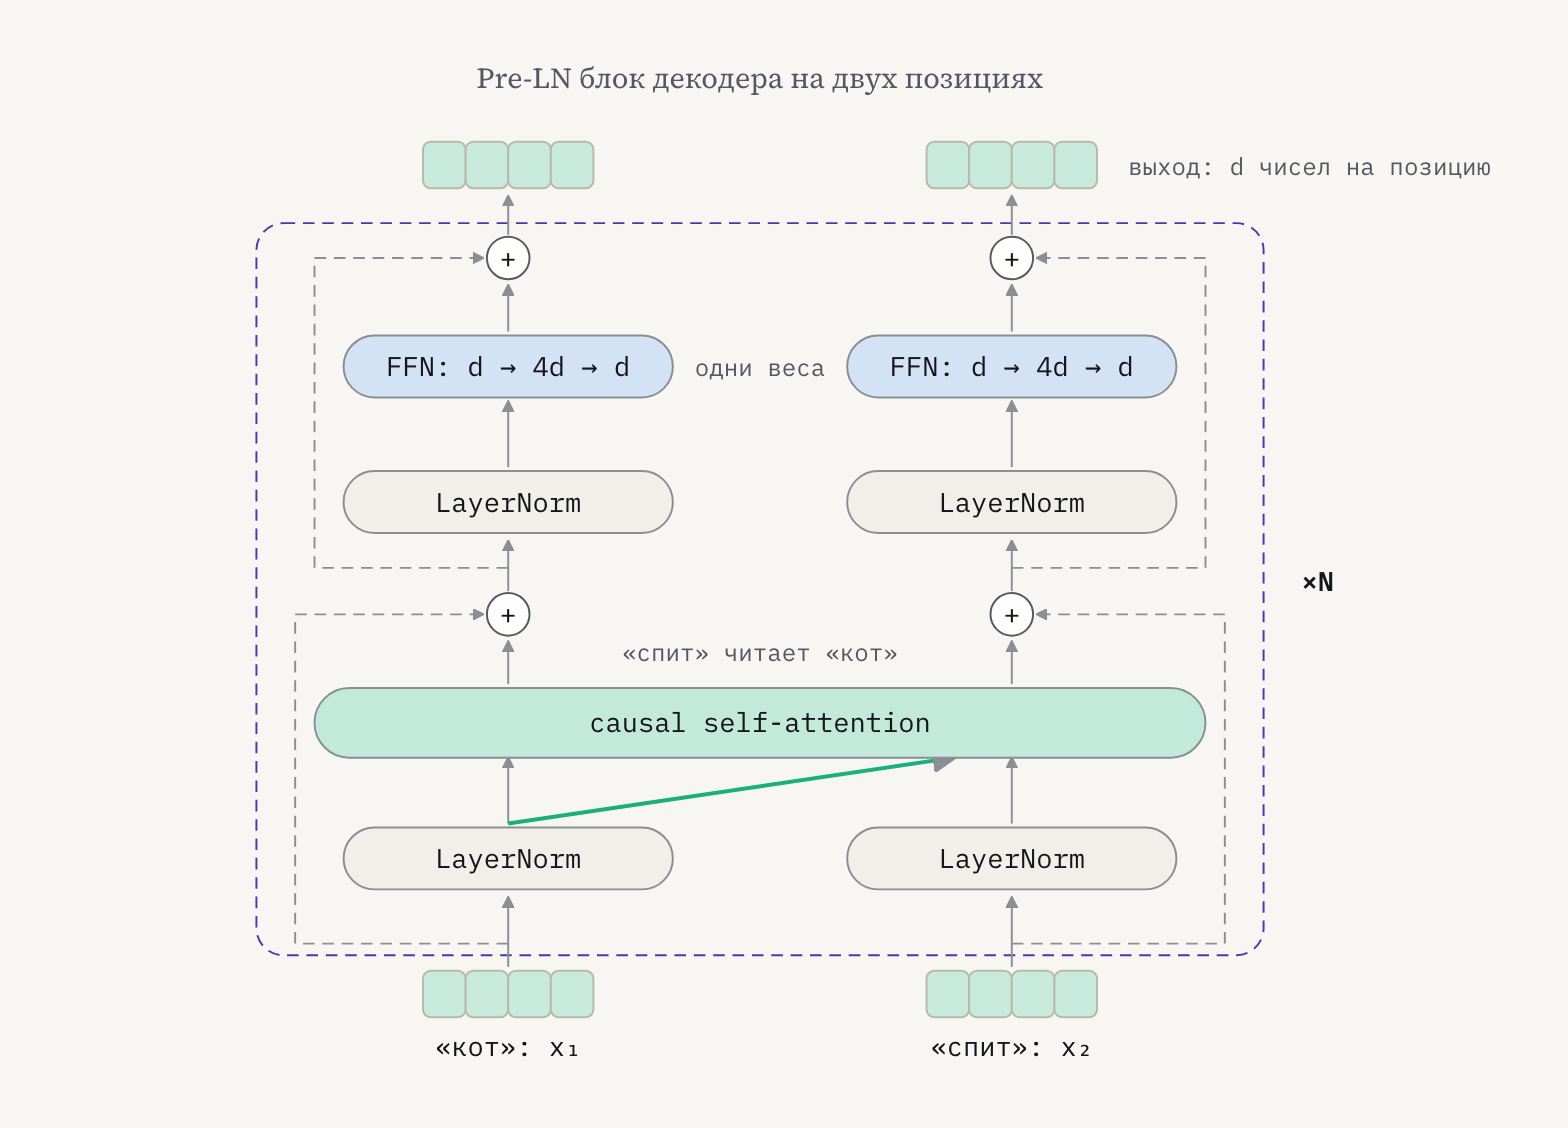

Маска запрещает читать будущие позиции и ключи PAD. Позиции PAD как запросы тоже дают выходы; соответствующие цели исключены из loss.

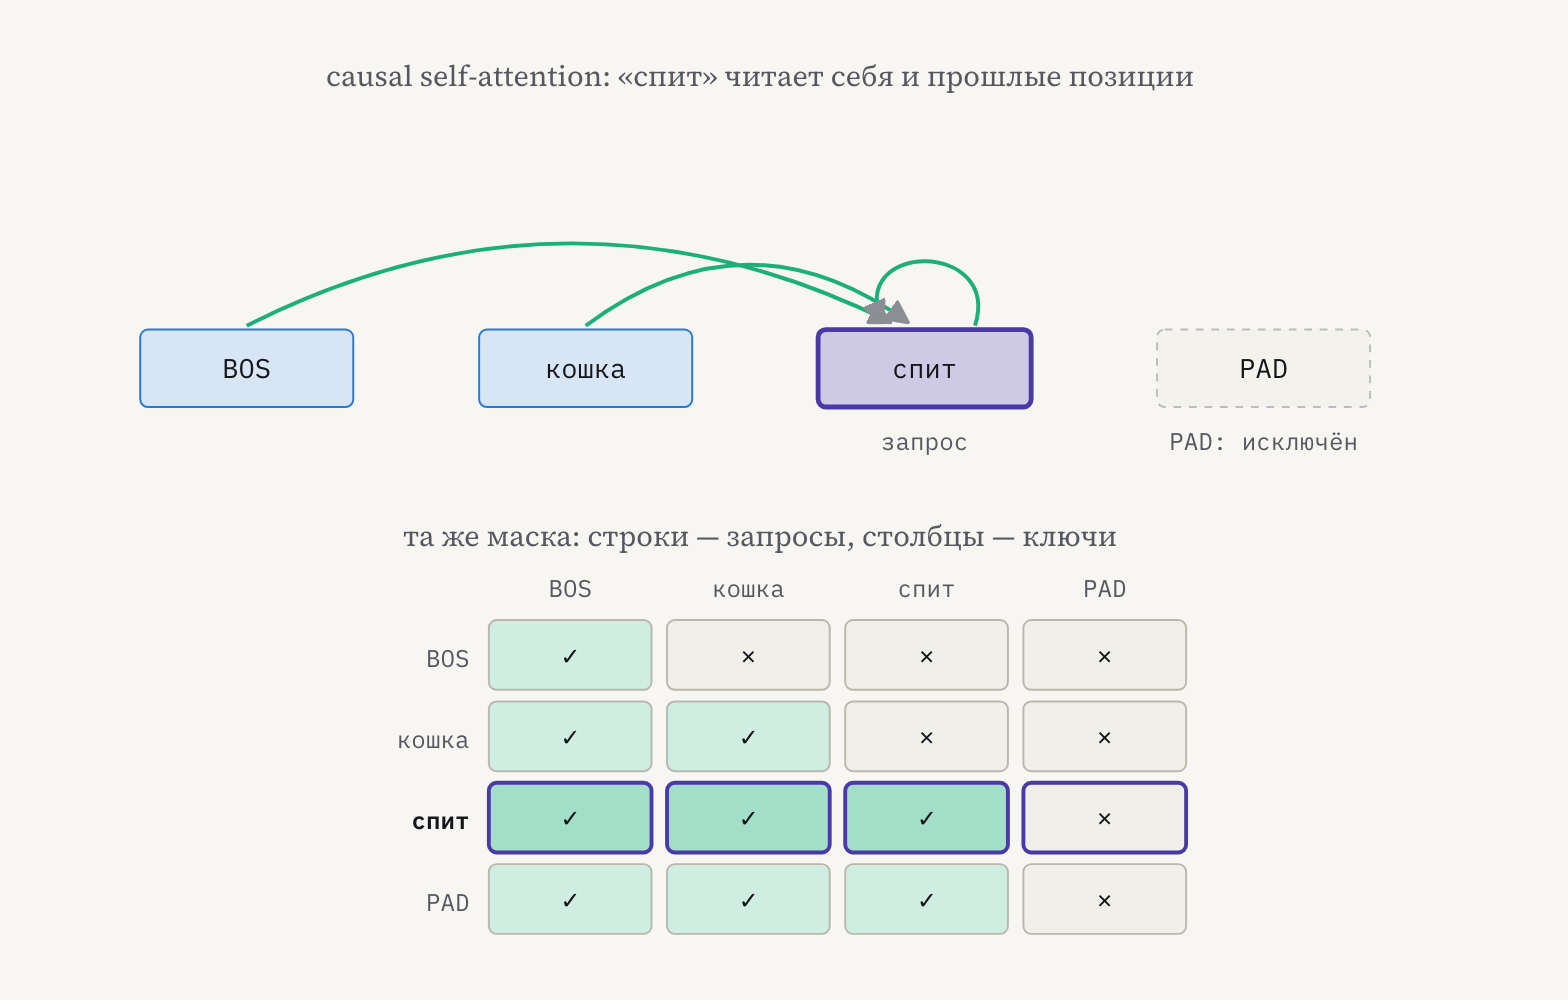

In [15]:
class TransformerBlock(nn.Module):
    def __init__(self, d=48, heads=3):
        super().__init__()
        self.norm1 = nn.LayerNorm(d)
        self.attention = MultiHeadSelfAttention(d, heads)
        self.norm2 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, allowed):
        x = x + self.attention(self.norm1(x), allowed)
        x = x + self.ffn(self.norm2(x))
        return x

def causal_mask(ids):
    length = ids.size(1)
    causal = torch.ones(length, length, dtype=torch.bool, device=ids.device).tril()
    return causal[None, None] & (ids != PAD)[:, None, None, :]

block = TransformerBlock()
x = torch.randn(2, 5, 48, requires_grad=True)
mask = torch.ones(5, 5, dtype=torch.bool).tril()
y = block(x, mask)
assert y.shape == x.shape
# Будущие позиции не должны влиять на префикс.
changed = x.detach().clone()
changed[:, 3:] += torch.randn_like(changed[:, 3:]) * 5
torch.testing.assert_close(y[:, :3], block(changed, mask)[:, :3])
y.square().mean().backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in block.parameters())
print("Размер сохранён, будущее закрыто, градиенты конечны.")

Размер сохранён, будущее закрыто, градиенты конечны.


### Из блока — языковая модель

Добавляем токенные и позиционные эмбеддинги, один блок, финальную нормализацию и выходной слой словаря. Позиционные эмбеддинги здесь обучаемые. Они определены только до `max_positions`; выход за этот предел проверяем явно.

Сохраняем данные, словарь, loss, обучение и генерацию из блока GRU. Меняется модель. Сравнение описывает именно эти две небольшие конфигурации, а не преимущество семейства архитектур.

In [16]:
class TransformerLanguageModel(nn.Module):
    def __init__(self, vocab_size, max_positions, d=48, heads=3):
        super().__init__()
        self.max_positions = max_positions
        self.embedding = nn.Embedding(vocab_size, d, padding_idx=PAD)
        self.position = nn.Embedding(max_positions, d)
        self.block = TransformerBlock(d, heads)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab_size)

    def hidden(self, ids):
        if ids.size(1) > self.max_positions:
            raise ValueError(f"Длина {ids.size(1)} превышает предел {self.max_positions}")
        positions = torch.arange(ids.size(1), device=ids.device)
        x = self.embedding(ids) + self.position(positions)
        return self.norm(self.block(x, causal_mask(ids)))

    def forward(self, ids):
        return self.head(self.hidden(ids))

    def next_logits(self, ids):
        if ids.size(1) > self.max_positions:
            raise ValueError("Префикс длиннее позиционной таблицы; сократите генерацию")
        return self.head(self.hidden(ids)[:, -1])

# BOS плюс максимальная длина текста во входе при обучении.
torch.manual_seed(SEED)
transformer = TransformerLanguageModel(len(lm_vocab), max_positions=lm_cap + 1).to(device)
train_language_model(transformer)
for name, model in [("GRU", gru), ("Трансформер", transformer)]:
    loss, ppl = language_scores(model, lm_test_loader)
    parameters = sum(p.numel() for p in model.parameters())
    print(f"{name}: параметры={parameters}; test loss={loss:.3f}; PPL={ppl:.2f}")
    print(generate(model, prefix="я", max_new_tokens=min(40, lm_cap - 1)))

Эпоха 1: 30/30, 188.9 батч/с, ETA 0 с
Обучение loss=6.116; проверка loss=4.021, PPL=55.77; 0.2 с
Эпоха 2: 30/30, 190.7 батч/с, ETA 0 с
Обучение loss=4.997; проверка loss=3.848, PPL=46.92; 0.2 с
GRU: параметры=208112; test loss=3.949; PPL=51.86
я [UNK] - и меня , , - [UNK] - [UNK] , не орать [UNK] раз .
Трансформер: параметры=225440; test loss=3.938; PPL=51.33
я [UNK] - и [UNK] , , - [UNK] - [UNK] , не орать [UNK] раз .


In [17]:
# Проверяем причинность всей модели с позициями и выходным слоем.
transformer.eval()
probe = torch.tensor([[BOS, 4, 5, 6, 7]])
changed = probe.clone()
changed[:, 3:] = torch.tensor([8, 9])
with torch.no_grad():
    torch.testing.assert_close(transformer(probe)[:, :3], transformer(changed)[:, :3])
    torch.testing.assert_close(transformer(probe), transformer(F.pad(probe, (0, 3)))[:, :5])
    logits = gru(inputs[:2])
    target = targets[:2]
    extended_logits = F.pad(logits, (0, 0, 0, 2))
    extended_target = F.pad(target, (0, 2), value=PAD)
    torch.testing.assert_close(token_loss(logits, target), token_loss(extended_logits, extended_target))
print("Вся модель закрывает будущее; PAD не меняет полезные выходы и loss.")

Вся модель закрывает будущее; PAD не меняет полезные выходы и loss.


## Что мы собрали

| Задача | Выход | Цель | Как получаем ответ |
|---|---|---|---|
| Классификация | B × C | B | argmax по классам |
| Языковая модель | B × T × V | B × T | последовательный выбор токенов |
| Блок трансформера | B × T × d | задаётся внешней задачей | преобразует представления |

Блок трансформера сам по себе не задаёт задачу и функцию потерь. Его можно включить в языковую модель или в классификатор с агрегацией по позициям. В переводчике декодер дополнительно читает источник через cross-attention.

**Попробуйте:** измените число голов, сохранив общую ширину модели и её делимость на число голов; добавьте второй блок; замените среднее в классификаторе выходом трансформера с полной маской. Сначала сформулируйте проверяемое ожидание, затем сравните на проверочной части. Итоговое сравнение архитектур потребует нескольких seed и большего бюджета.


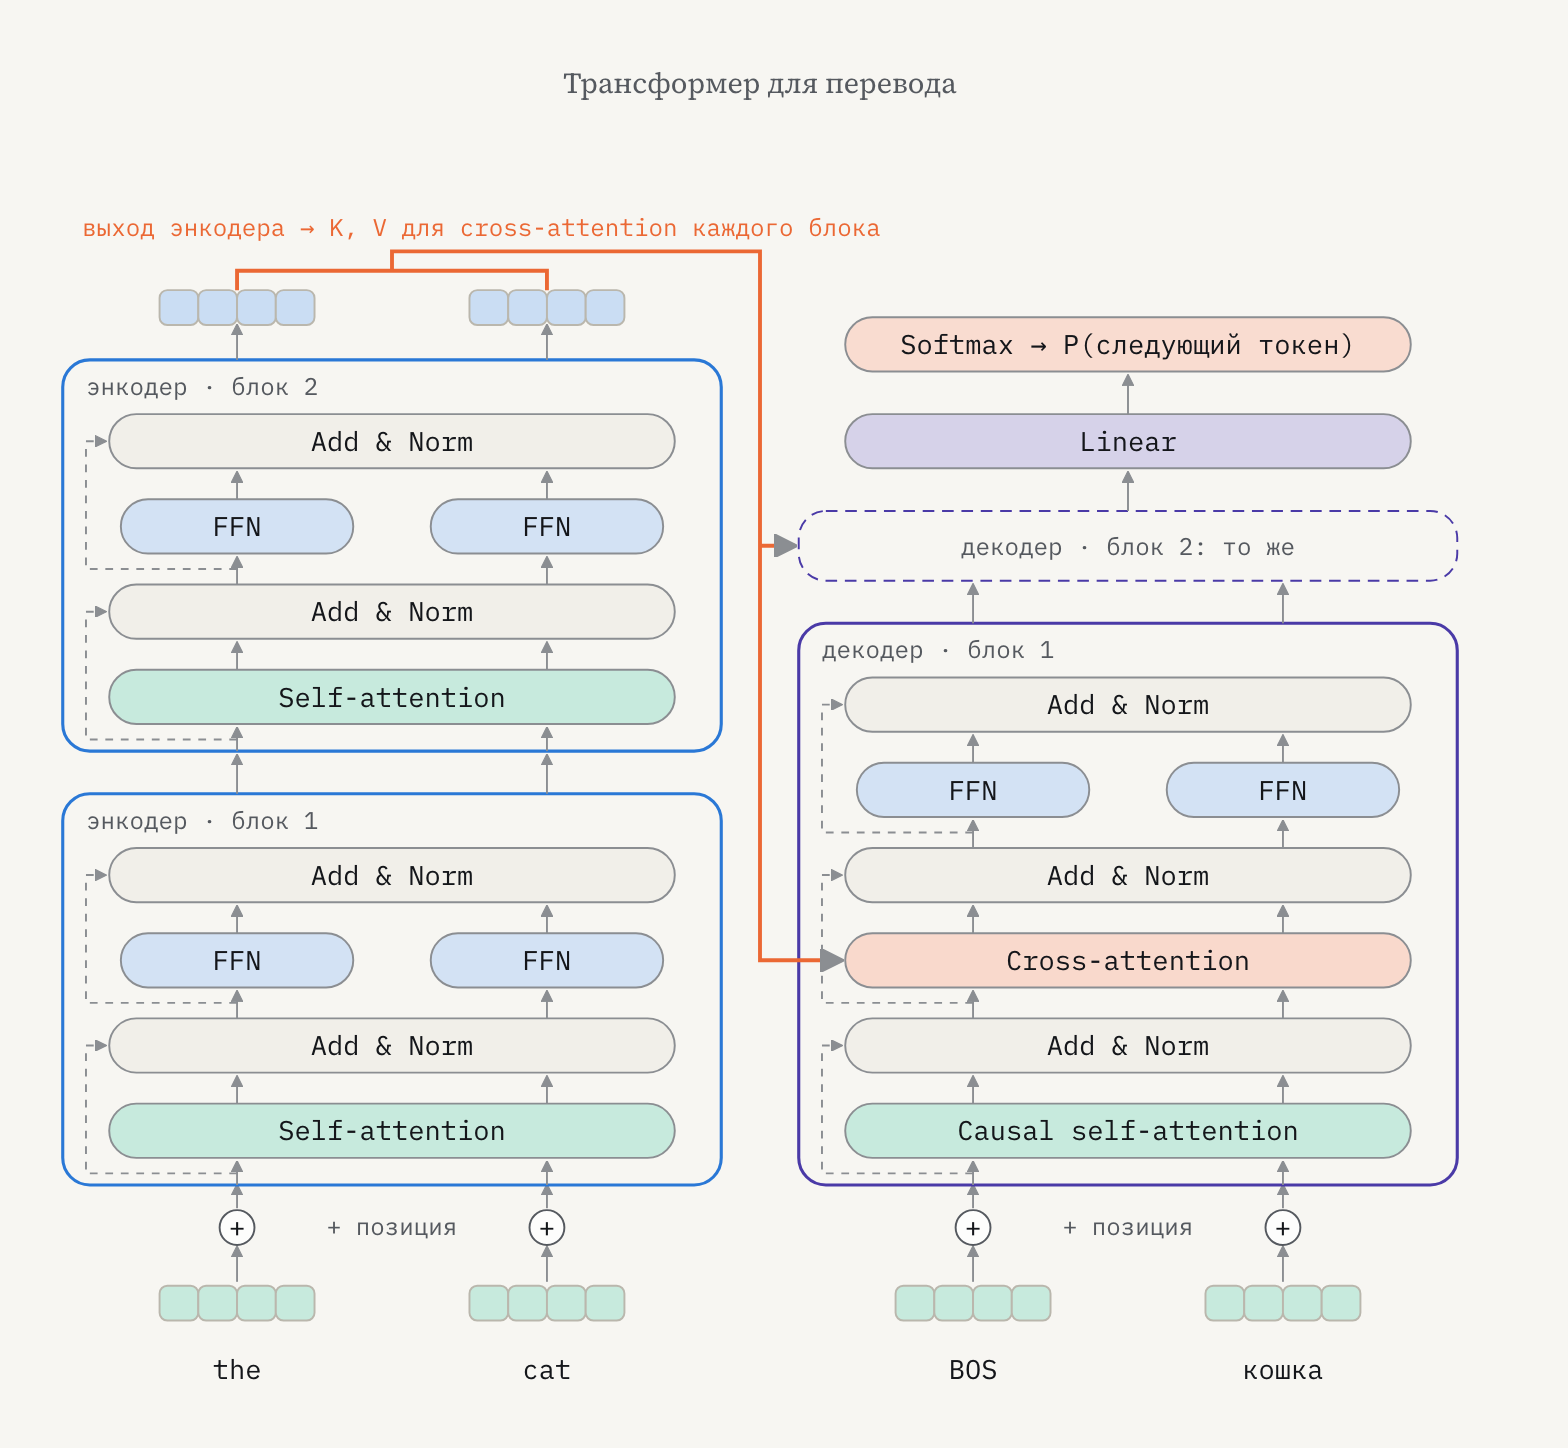

## Источники

* Mikolov et al. (2013). [*Distributed Representations of Words and Phrases and their Compositionality.*](https://arxiv.org/abs/1310.4546) NeurIPS. — skip-gram и negative sampling.
* Pennington, Socher & Manning (2014). [*GloVe: Global Vectors for Word Representation.*](https://aclanthology.org/D14-1162/) EMNLP. — готовые векторы glove-wiki-gigaword-100.
* Bahdanau, Cho & Bengio (2015). [*Neural Machine Translation by Jointly Learning to Align and Translate.*](https://arxiv.org/abs/1409.0473) ICLR.
* Vaswani et al. (2017). [*Attention Is All You Need.*](https://arxiv.org/abs/1706.03762) NeurIPS.

Схемы: страницы ADD занятий 1–3, автор Daria Andreeva. В ноутбук вложены SVG и растровая копия тех же схем для совместимости с просмотрщиками.